In [23]:
import pandas as pd
import numpy as np
from pathlib import Path
from statsmodels.stats.proportion import proportion_confint

# --------------------------------------------------
# PATHS
# --------------------------------------------------

BASE_DIR = Path(
    r"C:/Users/CH.SC.U4CSE23160/Neural Project/IndicHallbench-Hallucinations-Benchmark"
)

ANNOTATION_PATH = (
    BASE_DIR / "data/annotations/final/final_annotations.csv"
)

ADJUDICATED_PATH = (
    BASE_DIR / "data/validation/adjudicated_annotations.csv"
)

OUTPUT_DIR = BASE_DIR / "results/LRS_analysis"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


# --------------------------------------------------
# LOAD DATA
# --------------------------------------------------

annotations = pd.read_csv(ANNOTATION_PATH)

human = pd.read_csv(ADJUDICATED_PATH)

# Required columns
required_annotation = [
    "response_id",
    "language",
    "model_name"
]

required_human = [
    "response_id",
    "final_correctness_label"
]

for col in required_annotation:
    if col not in annotations.columns:
        raise KeyError(f"Missing annotation column: {col}")

for col in required_human:
    if col not in human.columns:
        raise KeyError(f"Missing human annotation column: {col}")


# --------------------------------------------------
# NORMALIZE IDENTIFIERS
# --------------------------------------------------

for df in [annotations, human]:
    df["response_id"] = (
        df["response_id"].astype("string").str.strip()
    )

if annotations["response_id"].duplicated().any():
    raise ValueError("Duplicate response_id in original annotations.")

if human["response_id"].duplicated().any():
    raise ValueError("Duplicate response_id in human annotations.")


# --------------------------------------------------
# MERGE HUMAN LABELS WITH LANGUAGE AND MODEL
# --------------------------------------------------

lrs_data = human.merge(
    annotations[
        ["response_id", "language", "model_name"]
    ],
    on="response_id",
    how="left",
    validate="one_to_one",
    indicator=True
)

if (lrs_data["_merge"] != "both").any():
    raise ValueError(
        "Some human-annotated response IDs could not be matched."
    )

lrs_data.drop(columns="_merge", inplace=True)

lrs_data["language"] = (
    lrs_data["language"].astype(str).str.strip().str.upper()
)

lrs_data["final_correctness_label"] = (
    lrs_data["final_correctness_label"].astype(str).str.strip()
)


# --------------------------------------------------
# VALIDATE LABELS
# --------------------------------------------------

VALID_LABELS = [
    "Correct",
    "Partially Correct",
    "Incorrect",
    "Uncertain"
]

invalid = set(
    lrs_data["final_correctness_label"].unique()
) - set(VALID_LABELS)

if invalid:
    raise ValueError(f"Unexpected labels: {invalid}")


# --------------------------------------------------
# DEFINE LRS
# --------------------------------------------------

def calculate_lrs(group):

    total = len(group)

    correct = (
        group["final_correctness_label"] == "Correct"
    ).sum()

    uncertain = (
        group["final_correctness_label"] == "Uncertain"
    ).sum()

    eligible = total - uncertain

    lrs = correct / eligible if eligible > 0 else np.nan

    uncertain_rate = (
        uncertain / total if total > 0 else np.nan
    )

    # Wilson 95% confidence interval
    if eligible > 0:
        ci_low, ci_high = proportion_confint(
            count=correct,
            nobs=eligible,
            alpha=0.05,
            method="wilson"
        )
    else:
        ci_low, ci_high = np.nan, np.nan

    return pd.Series({
        "total_responses": total,
        "correct": correct,
        "partially_correct": (
            group["final_correctness_label"]
            == "Partially Correct"
        ).sum(),
        "incorrect": (
            group["final_correctness_label"]
            == "Incorrect"
        ).sum(),
        "uncertain": uncertain,
        "eligible_responses": eligible,
        "LRS": lrs,
        "LRS_95CI_lower": ci_low,
        "LRS_95CI_upper": ci_high,
        "uncertain_rate": uncertain_rate
    })


# --------------------------------------------------
# TABLE A: LANGUAGE-WISE LRS
# --------------------------------------------------

language_lrs = (
    lrs_data.groupby("language")
    .apply(calculate_lrs, include_groups=False)
    .reset_index()
)

language_lrs = language_lrs.sort_values(
    "LRS",
    ascending=False
)

display(language_lrs.round(4))

language_lrs.to_csv(
    OUTPUT_DIR / "language_wise_LRS_human.csv",
    index=False
)


# --------------------------------------------------
# TABLE B: MODEL × LANGUAGE LRS
# --------------------------------------------------

model_language_lrs = (
    lrs_data.groupby(
        ["model_name", "language"]
    )
    .apply(calculate_lrs, include_groups=False)
    .reset_index()
)

model_language_pivot = model_language_lrs.pivot(
    index="model_name",
    columns="language",
    values="LRS"
)

display(model_language_pivot.round(4))

model_language_lrs.to_csv(
    OUTPUT_DIR / "model_language_LRS_human.csv",
    index=False
)

model_language_pivot.to_csv(
    OUTPUT_DIR / "model_language_LRS_matrix.csv"
)


# --------------------------------------------------
# INTERPRETATION BANDS
# --------------------------------------------------

def interpret_lrs(value):

    if pd.isna(value):
        return "Not estimable"

    if value >= 0.90:
        return "Very High Reliability"

    elif value >= 0.75:
        return "High Reliability"

    elif value >= 0.50:
        return "Moderate Reliability"

    return "Low Reliability"


language_lrs["interpretation"] = (
    language_lrs["LRS"].apply(interpret_lrs)
)

display(language_lrs.round(4))

language_lrs.to_csv(
    OUTPUT_DIR / "language_wise_LRS_final.csv",
    index=False
)


print("\nLRS analysis completed.")
print("Results saved to:", OUTPUT_DIR)

,language,total_responses,correct,partially_correct,incorrect,uncertain,eligible_responses,LRS,LRS_95CI_lower,LRS_95CI_upper,uncertain_rate
0,EN,600.0,501.0,82.0,17.0,0.0,600.0,0.8350,0.8032,0.8626,0.0000
1,HI,600.0,474.0,112.0,10.0,4.0,596.0,0.7953,0.7611,0.8258,0.0067
4,TA,600.0,464.0,117.0,19.0,0.0,600.0,0.7733,0.7382,0.8050,0.0000
3,NE,600.0,460.0,107.0,28.0,5.0,595.0,0.7731,0.7378,0.8049,0.0083
2,HI-EN,600.0,454.0,133.0,11.0,2.0,598.0,0.7592,0.7233,0.7917,0.0033
5,TE,600.0,450.0,127.0,21.0,2.0,598.0,0.7525,0.7164,0.7854,0.0033


language,EN,HI,HI-EN,NE,TA,TE
model_name,,,,,,
Claude Sonnet 5.5,0.90,0.8300,0.7576,0.7755,0.77,0.7755
DeepSeek-V4.1-Flash,0.84,0.8081,0.7400,0.8200,0.74,0.7500
GLM-5.3 Flash,0.87,0.8300,0.8100,0.8400,0.83,0.7600
GPT-5.6 Luna,0.75,0.8081,0.6768,0.7475,0.75,0.7900
Gemini 3,0.80,0.7245,0.7800,0.7449,0.79,0.7000
Qwen 3.7,0.85,0.7700,0.7900,0.7100,0.76,0.7400


,language,total_responses,correct,partially_correct,incorrect,uncertain,eligible_responses,LRS,LRS_95CI_lower,LRS_95CI_upper,uncertain_rate,interpretation
0,EN,600.0,501.0,82.0,17.0,0.0,600.0,0.8350,0.8032,0.8626,0.0000,High Reliability
1,HI,600.0,474.0,112.0,10.0,4.0,596.0,0.7953,0.7611,0.8258,0.0067,High Reliability
4,TA,600.0,464.0,117.0,19.0,0.0,600.0,0.7733,0.7382,0.8050,0.0000,High Reliability
3,NE,600.0,460.0,107.0,28.0,5.0,595.0,0.7731,0.7378,0.8049,0.0083,High Reliability
2,HI-EN,600.0,454.0,133.0,11.0,2.0,598.0,0.7592,0.7233,0.7917,0.0033,High Reliability
5,TE,600.0,450.0,127.0,21.0,2.0,598.0,0.7525,0.7164,0.7854,0.0033,High Reliability



LRS analysis completed.
Results saved to: C:\Users\CH.SC.U4CSE23160\Neural Project\IndicHallbench-Hallucinations-Benchmark\results\LRS_analysis


Figure 9 matrix:


language,EN,HI,HI-EN,NE,TA,TE
model_name,,,,,,
Claude Sonnet 5.5,0.90,0.8300,0.7576,0.7755,0.77,0.7755
DeepSeek-V4.1-Flash,0.84,0.8081,0.7400,0.8200,0.74,0.7500
GLM-5.3 Flash,0.87,0.8300,0.8100,0.8400,0.83,0.7600
GPT-5.6 Luna,0.75,0.8081,0.6768,0.7475,0.75,0.7900
Gemini 3,0.80,0.7245,0.7800,0.7449,0.79,0.7000
Qwen 3.7,0.85,0.7700,0.7900,0.7100,0.76,0.7400


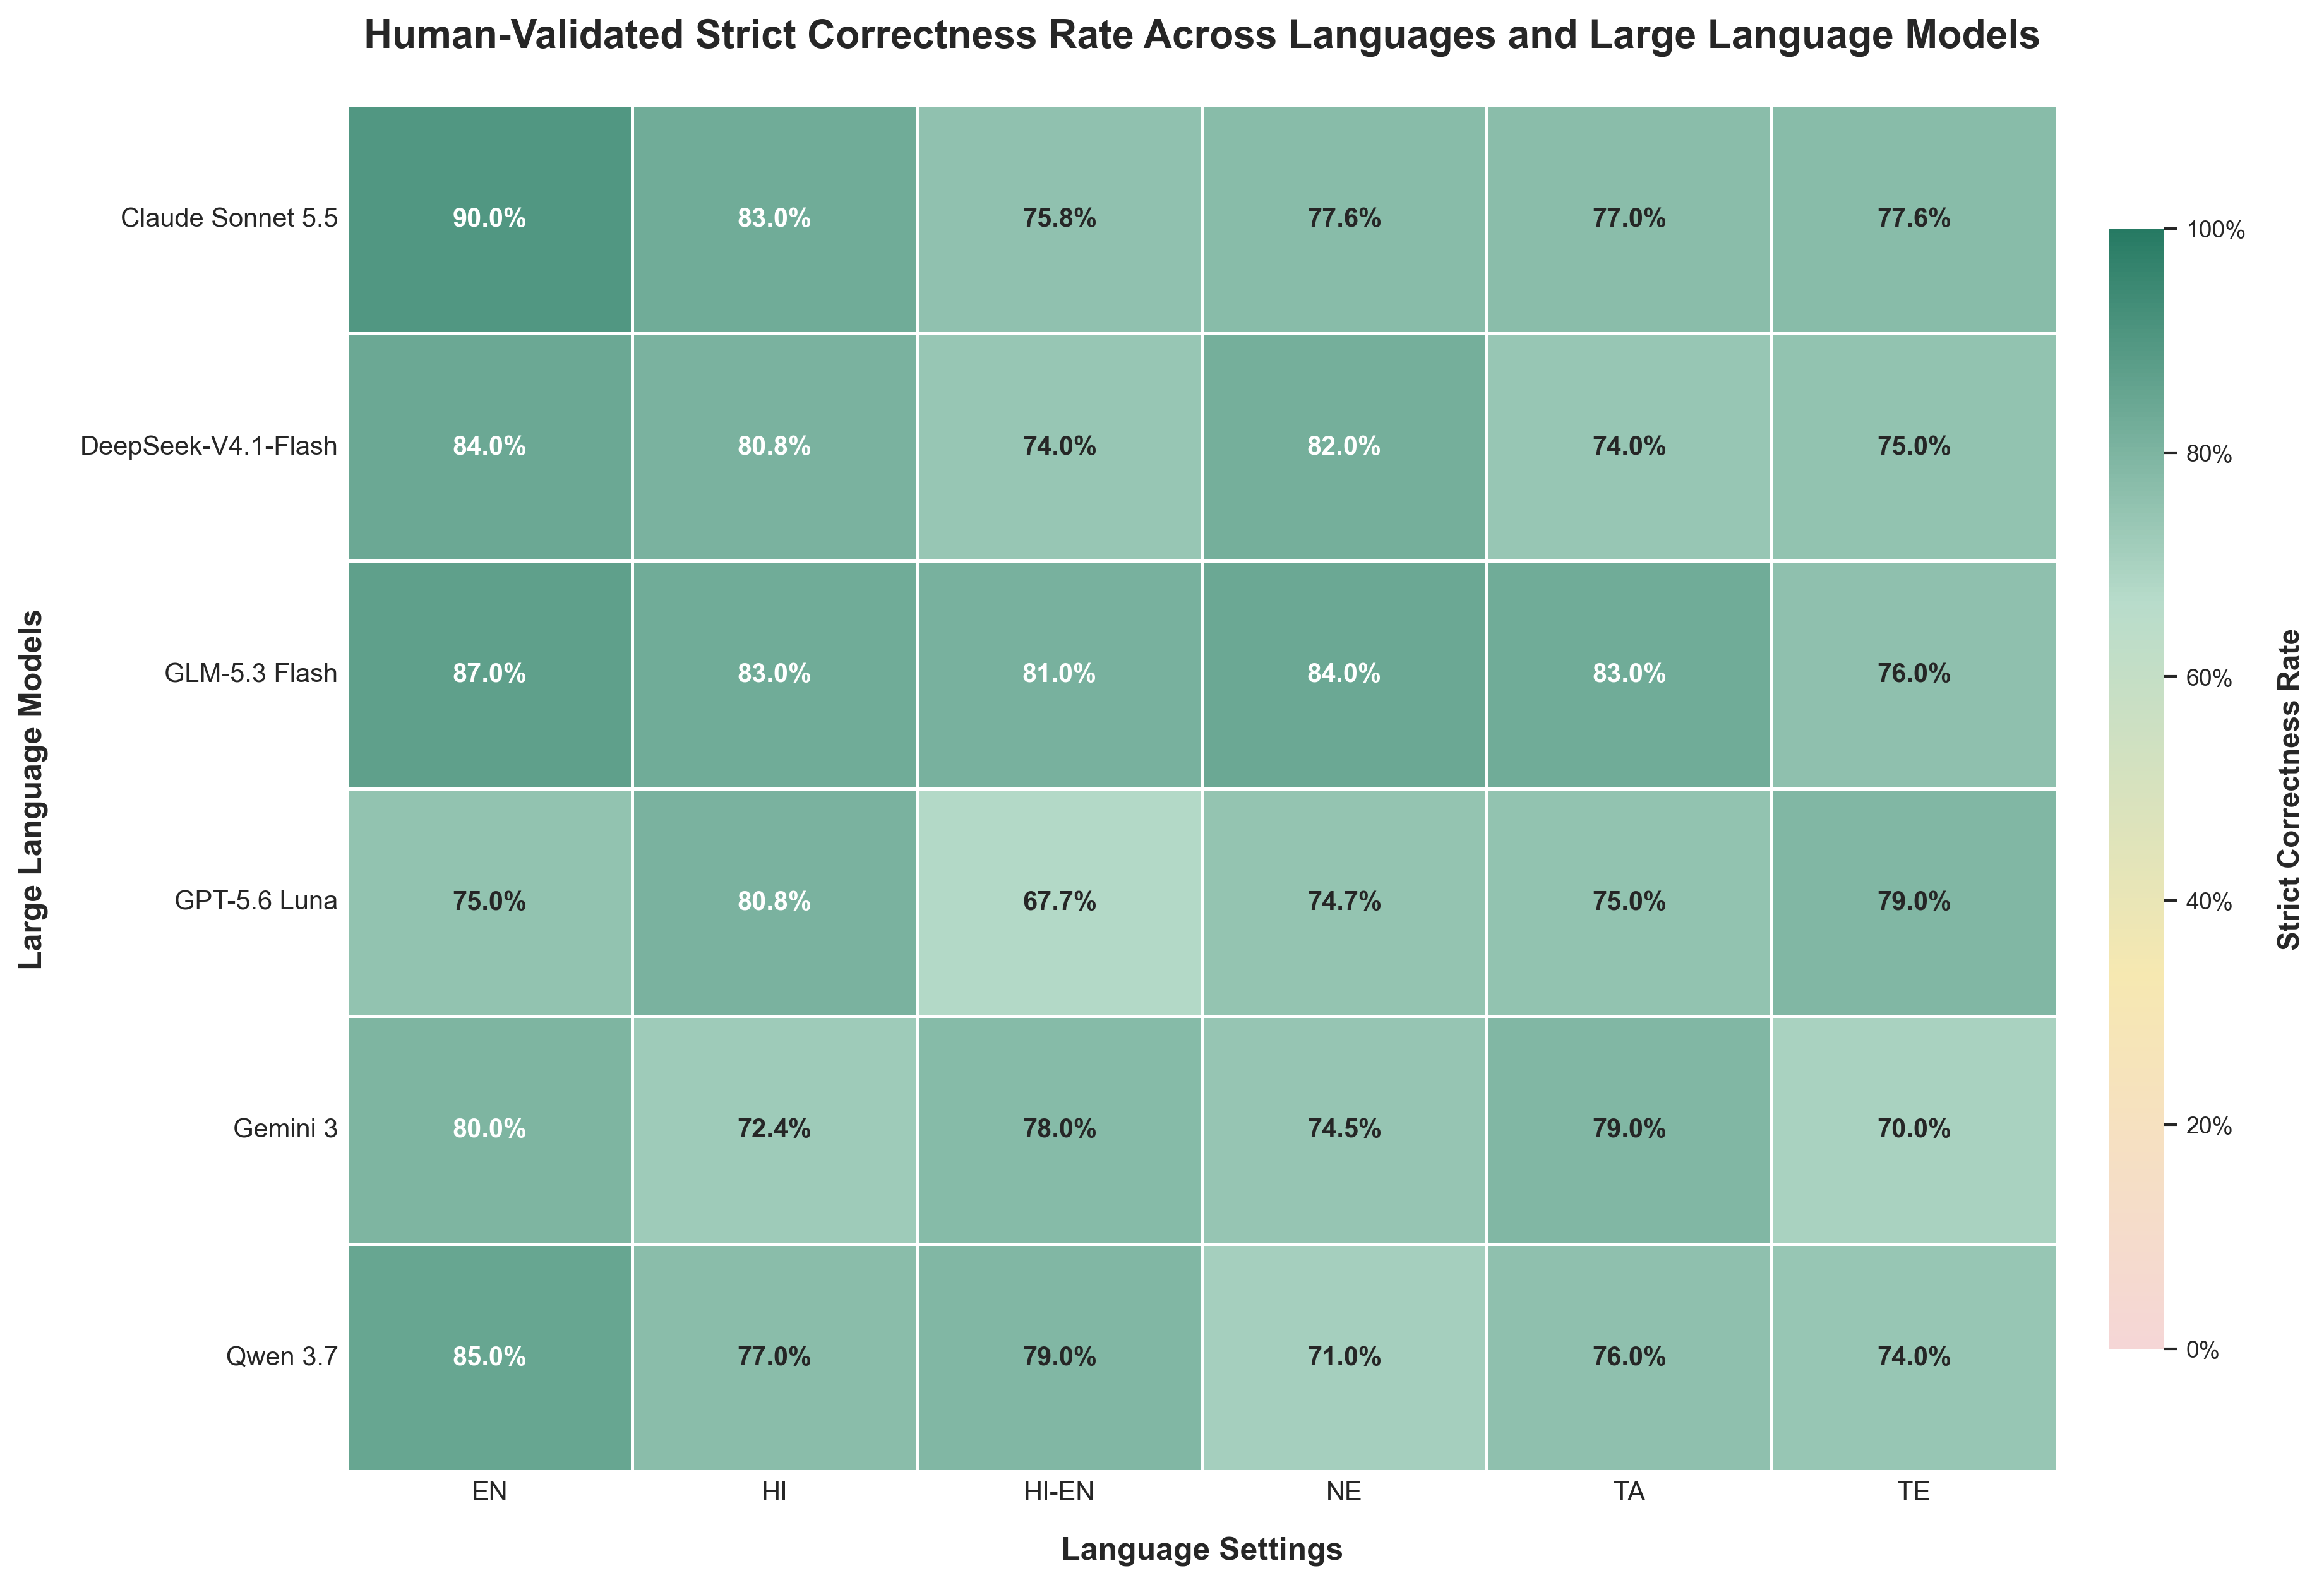


FIGURE 9: HEATMAP SUMMARY
Language settings: 6
LLMs evaluated: 6
Available model-language combinations: 36
Missing combinations: 0
Mean LRS: 0.7813
Highest LRS: 0.9
Lowest LRS: 0.6768

Figure 9 exported successfully.
Output directory: C:\Users\CH.SC.U4CSE23160\Neural Project\IndicHallbench-Hallucinations-Benchmark\results\LRS_analysis\figures


In [24]:

# ============================================================
# FIGURE 9: LANGUAGE × LLM HUMAN-VALIDATED LRS HEATMAP
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from pathlib import Path

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

FIGURE_DIR = OUTPUT_DIR / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

FIGURE_9_TITLE = (
    "Human-Validated Strict Correctness Rate Across "
    "Languages and Large Language Models"
)

# Expected six language settings
LANGUAGE_ORDER = sorted(
    lrs_data["language"].dropna().unique().tolist()
)

# Expected six LLMs
MODEL_ORDER = sorted(
    lrs_data["model_name"].dropna().unique().tolist()
)

# Validate dimensions
if len(LANGUAGE_ORDER) != 6:
    raise ValueError(
        f"Expected 6 language settings, found "
        f"{len(LANGUAGE_ORDER)}: {LANGUAGE_ORDER}"
    )

if len(MODEL_ORDER) != 6:
    raise ValueError(
        f"Expected 6 LLMs, found "
        f"{len(MODEL_ORDER)}: {MODEL_ORDER}"
    )

# ------------------------------------------------------------
# 2. CREATE LRS MATRIX
# ------------------------------------------------------------

figure9_data = (
    model_language_lrs
    .pivot(
        index="model_name",
        columns="language",
        values="LRS"
    )
    .reindex(
        index=MODEL_ORDER,
        columns=LANGUAGE_ORDER
    )
)

# Save exact plotted values
figure9_data.to_csv(
    FIGURE_DIR / "Figure9_LRS_heatmap_data.csv"
)

print("Figure 9 matrix:")
display(figure9_data.round(4))

# ------------------------------------------------------------
# 3. CUSTOM PUBLICATION COLOUR MAP
# ------------------------------------------------------------

cmap = LinearSegmentedColormap.from_list(
    "publication_lrs",
    [
        "#F5D6D6",  # Lower strict correctness
        "#F6E8B1",  # Moderate
        "#B8DCCB",  # High
        "#267A63"   # Very high
    ],
    N=256
)

cmap.set_bad("#D9D9D9")

# ------------------------------------------------------------
# 4. PREPARE CELL ANNOTATIONS
# ------------------------------------------------------------

annotations_matrix = figure9_data.copy().astype(object)

for i in range(figure9_data.shape[0]):
    for j in range(figure9_data.shape[1]):

        value = figure9_data.iloc[i, j]

        if pd.isna(value):
            annotations_matrix.iloc[i, j] = "N/A"
        else:
            annotations_matrix.iloc[i, j] = (
                f"{value * 100:.1f}%"
            )

# ------------------------------------------------------------
# 5. GENERATE HEATMAP
# ------------------------------------------------------------

sns.set_theme(
    style="white",
    context="paper",
    font_scale=1.15
)

fig, ax = plt.subplots(
    figsize=(13, 8.5),
    dpi=300
)

heatmap = sns.heatmap(
    figure9_data,
    annot=annotations_matrix,
    fmt="",
    cmap=cmap,
    vmin=0,
    vmax=1,
    center=0.5,
    linewidths=1.2,
    linecolor="white",
    square=False,
    mask=figure9_data.isna(),
    cbar_kws={
        "label": "Strict Correctness Rate (LRS)",
        "shrink": 0.82,
        "pad": 0.025,
        "ticks": np.linspace(0, 1, 6),
        "format": "%.0f"
    },
    annot_kws={
        "fontsize": 10,
        "fontweight": "bold"
    },
    ax=ax
)

# Add N/A labels to missing combinations
for i in range(figure9_data.shape[0]):
    for j in range(figure9_data.shape[1]):
        if pd.isna(figure9_data.iloc[i, j]):
            ax.text(
                j + 0.5,
                i + 0.5,
                "N/A",
                ha="center",
                va="center",
                fontsize=9,
                color="#555555"
            )

# ------------------------------------------------------------
# 6. AXIS FORMATTING
# ------------------------------------------------------------

ax.set_title(
    FIGURE_9_TITLE,
    fontsize=15,
    fontweight="bold",
    pad=22
)

ax.set_xlabel(
    "Language Settings",
    fontsize=12,
    fontweight="bold",
    labelpad=12
)

ax.set_ylabel(
    "Large Language Models",
    fontsize=12,
    fontweight="bold",
    labelpad=12
)

ax.set_xticklabels(
    ax.get_xticklabels(),
    rotation=0,
    ha="center",
    fontsize=10
)

ax.set_yticklabels(
    ax.get_yticklabels(),
    rotation=0,
    fontsize=10
)

# ------------------------------------------------------------
# 7. COLORBAR FORMATTING
# ------------------------------------------------------------

colorbar = heatmap.collections[0].colorbar

colorbar.set_label(
    "Strict Correctness Rate",
    fontsize=11,
    fontweight="bold",
    labelpad=12
)

colorbar.set_ticks(
    np.linspace(0, 1, 6)
)

colorbar.set_ticklabels(
    [f"{x:.0%}" for x in np.linspace(0, 1, 6)]
)

colorbar.ax.tick_params(labelsize=9)

# ------------------------------------------------------------
# 8. GRID AND LAYOUT
# ------------------------------------------------------------

ax.tick_params(
    axis="both",
    which="both",
    length=0
)

sns.despine(
    left=True,
    bottom=True
)

plt.tight_layout()

# ------------------------------------------------------------
# 9. EXPORT PUBLICATION-QUALITY FIGURES
# ------------------------------------------------------------

fig.savefig(
    FIGURE_DIR / "Figure9_LRS_Heatmap.png",
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    FIGURE_DIR / "Figure9_LRS_Heatmap.pdf",
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    FIGURE_DIR / "Figure9_LRS_Heatmap.svg",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

plt.close(fig)

# ------------------------------------------------------------
# 10. SUMMARY STATISTICS
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("FIGURE 9: HEATMAP SUMMARY")
print("=" * 65)

print("Language settings:", len(LANGUAGE_ORDER))
print("LLMs evaluated:", len(MODEL_ORDER))

print(
    "Available model-language combinations:",
    int(figure9_data.notna().sum().sum())
)

print(
    "Missing combinations:",
    int(figure9_data.isna().sum().sum())
)

print(
    "Mean LRS:",
    round(figure9_data.stack().mean(), 4)
)

print(
    "Highest LRS:",
    round(figure9_data.stack().max(), 4)
)

print(
    "Lowest LRS:",
    round(figure9_data.stack().min(), 4)
)

print("\nFigure 9 exported successfully.")
print("Output directory:", FIGURE_DIR)